# 📊 Notebook 02: Feature Visualization — LFCC vs Log-Mel vs MFCC

**Project**: AudioShield — Multi-Granularity Temporal Attention for Explainable Audio Deepfake Detection  
**Author**: Abhinay Nama  

---

## Purpose
This notebook visually demonstrates:
1. **Why LFCC outperforms Log-Mel and MFCC** for anti-spoofing (linear vs Mel scale)
2. **Real vs Fake spectrogram differences** visible across all three features
3. **SpecAugment effects** on LFCC features
4. **Delta and Delta-Delta coefficient dynamics** across time
5. **CMVN normalization** effect on raw features

All extractors are from `src/features/extractor.py`.


In [1]:
import sys
sys.path.append('..')

import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
import matplotlib.ticker as ticker

from src.config import config
from src.features.extractor import LFCCExtractor, LogMelExtractor, MFCCExtractor, get_extractor
from src.data.dataset import ASVspoofDataset
from src.data.augmentation import SpecAugment

# Style
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'PyTorch: {torch.__version__}')

Device: cuda
PyTorch: 2.14.0+cu130


In [2]:
# ── Load real ASVspoof 2019 LA samples (no synthetic fallback) ─────────────
ds = ASVspoofDataset(
    protocol_path=config.paths.train_protocol,
    audio_dir=config.paths.train_audio_dir,
    is_train=False,  # deterministic crop
    auto_generate_dummy=False,
)

# Get one bonafide and one spoofed sample
real_wf, real_lbl, real_atk, real_id = None, None, None, None
fake_wf, fake_lbl, fake_atk, fake_id = None, None, None, None

for wf, lbl, atk, uid in ds:
    if real_wf is None and lbl.item() == 1:
        real_wf, real_lbl, real_atk, real_id = wf, lbl, atk, uid
    if fake_wf is None and lbl.item() == 0:
        fake_wf, fake_lbl, fake_atk, fake_id = wf, lbl, atk, uid
    if real_wf is not None and fake_wf is not None:
        break

real_wf = real_wf.unsqueeze(0).to(device)  # [1, 1, 64000]
fake_wf = fake_wf.unsqueeze(0).to(device)
print(f'Bonafide: {real_id}  |  Spoof ({real_atk}): {fake_id}')
print(f'Waveform shape: {real_wf.shape}')

[Dataset] Loaded 25380 samples from ASVspoof2019.LA.cm.train.trn.txt


Bonafide: LA_T_1138215  |  Spoof (bonafide): LA_T_1004644
Waveform shape: torch.Size([1, 1, 64000])


## 1. Raw Waveforms — Bonafide vs Spoof

/tmp/ipykernel_65289/2813943794.py:16: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_65289/2813943794.py:16: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/mnt/shared/VIT/DL/Project/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/mnt/shared/VIT/DL/Project/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


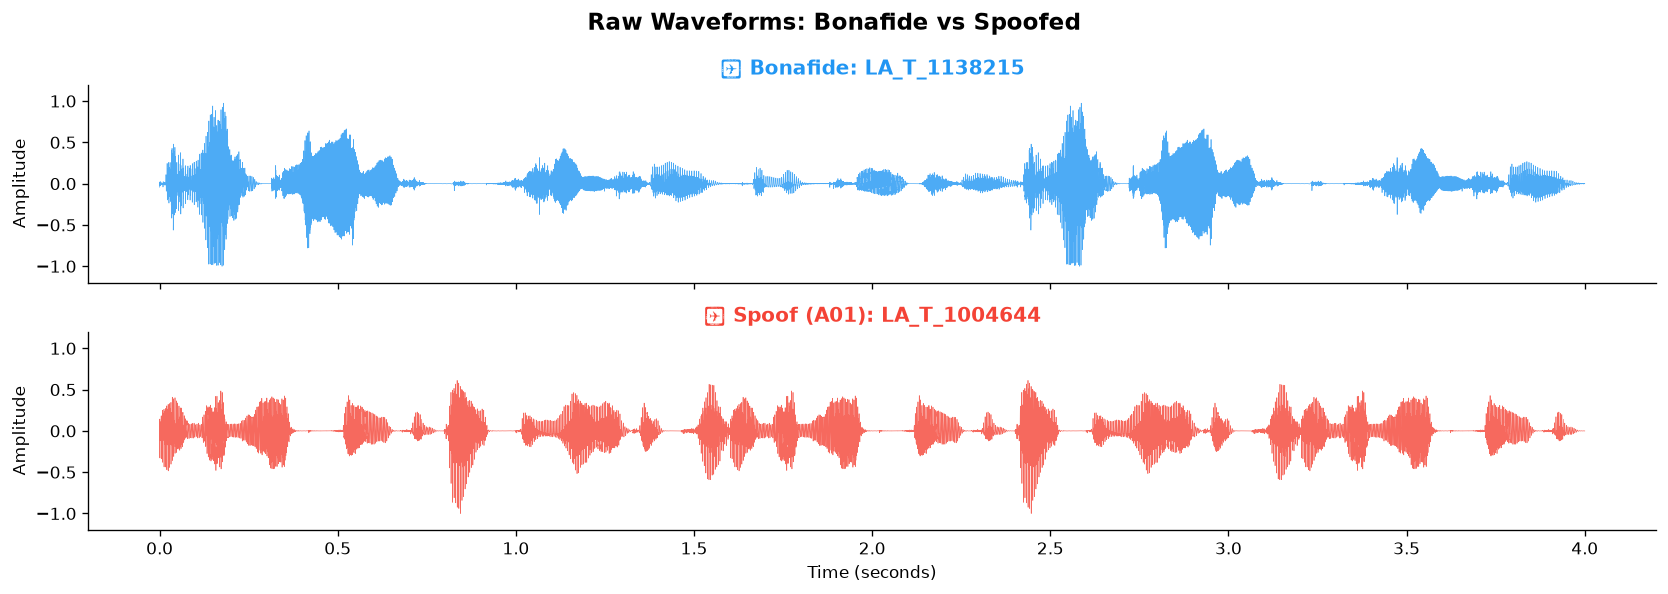

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
t = np.linspace(0, 4.0, 64000)

axes[0].plot(t, real_wf.squeeze().cpu().numpy(), color='#2196F3', linewidth=0.4, alpha=0.8)
axes[0].set_title(f'✅ Bonafide: {real_id}', fontweight='bold', color='#2196F3')
axes[0].set_ylabel('Amplitude')
axes[0].set_ylim(-1.2, 1.2)

axes[1].plot(t, fake_wf.squeeze().cpu().numpy(), color='#F44336', linewidth=0.4, alpha=0.8)
axes[1].set_title(f'❌ Spoof ({fake_atk}): {fake_id}', fontweight='bold', color='#F44336')
axes[1].set_ylabel('Amplitude')
axes[1].set_xlabel('Time (seconds)')
axes[1].set_ylim(-1.2, 1.2)

plt.suptitle('Raw Waveforms: Bonafide vs Spoofed', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 2. LFCC vs Log-Mel vs MFCC — Side-by-Side Comparison

**Key insight**: LFCC uses a **linear** frequency scale → equal resolution across 0–8 kHz.  
Log-Mel and MFCC use **Mel scale** → compresses 4–8 kHz where vocoder artifacts live.

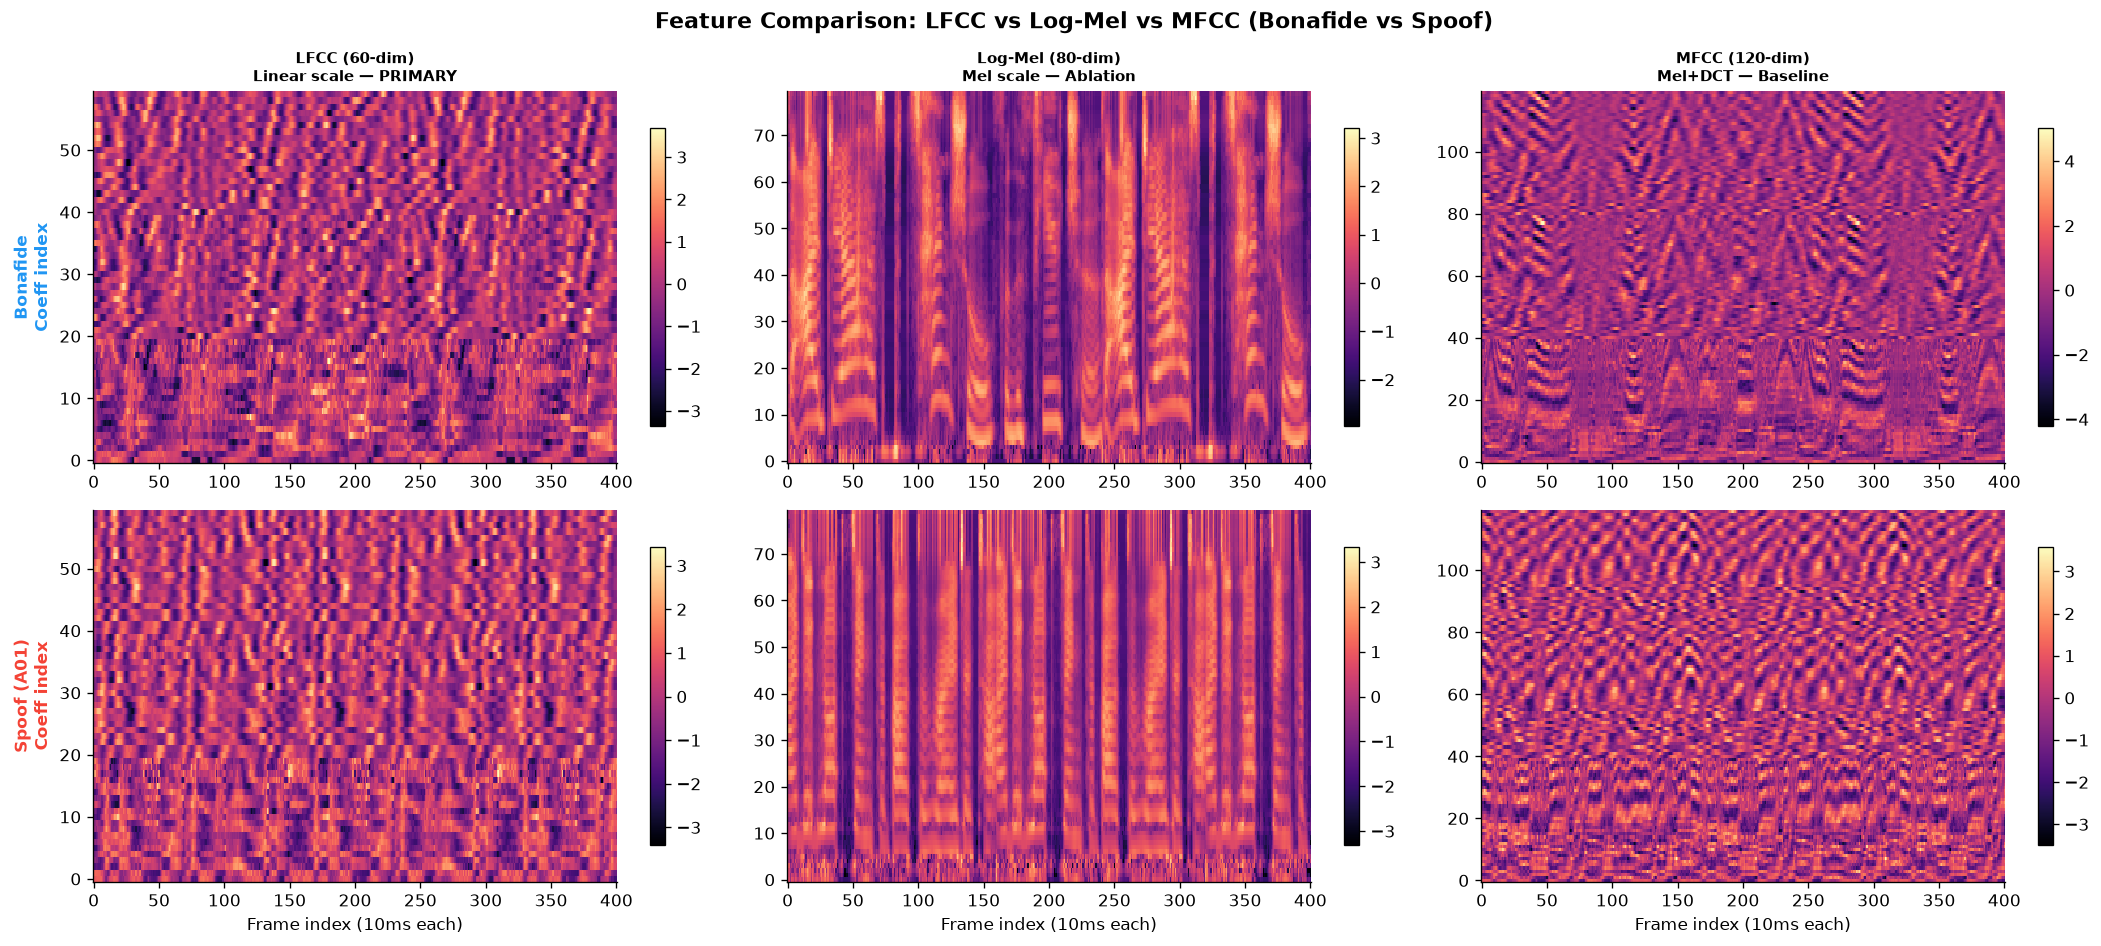

In [4]:
extractors = {
    'LFCC (60-dim)\nLinear scale — PRIMARY': LFCCExtractor().to(device).eval(),
    'Log-Mel (80-dim)\nMel scale — Ablation': LogMelExtractor().to(device).eval(),
    'MFCC (120-dim)\nMel+DCT — Baseline': MFCCExtractor().to(device).eval(),
}

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
cmap = 'magma'

with torch.no_grad():
    for col, (name, ext) in enumerate(extractors.items()):
        real_feat = ext(real_wf).squeeze(0).cpu().numpy()   # [n_coeffs, T]
        fake_feat = ext(fake_wf).squeeze(0).cpu().numpy()

        # Row 0: Bonafide
        im = axes[0, col].imshow(real_feat, aspect='auto', origin='lower',
                                  cmap=cmap, interpolation='nearest')
        axes[0, col].set_title(name, fontsize=9, fontweight='bold')
        axes[0, col].set_ylabel('Coeff index' if col == 0 else '')
        plt.colorbar(im, ax=axes[0, col], shrink=0.8)

        # Row 1: Spoof
        im = axes[1, col].imshow(fake_feat, aspect='auto', origin='lower',
                                  cmap=cmap, interpolation='nearest')
        axes[1, col].set_xlabel('Frame index (10ms each)')
        axes[1, col].set_ylabel('Coeff index' if col == 0 else '')
        plt.colorbar(im, ax=axes[1, col], shrink=0.8)

axes[0, 0].set_ylabel('Bonafide\nCoeff index', fontweight='bold', color='#2196F3')
axes[1, 0].set_ylabel(f'Spoof ({fake_atk})\nCoeff index', fontweight='bold', color='#F44336')

plt.suptitle('Feature Comparison: LFCC vs Log-Mel vs MFCC (Bonafide vs Spoof)', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. LFCC Static vs Δ vs ΔΔ Coefficients

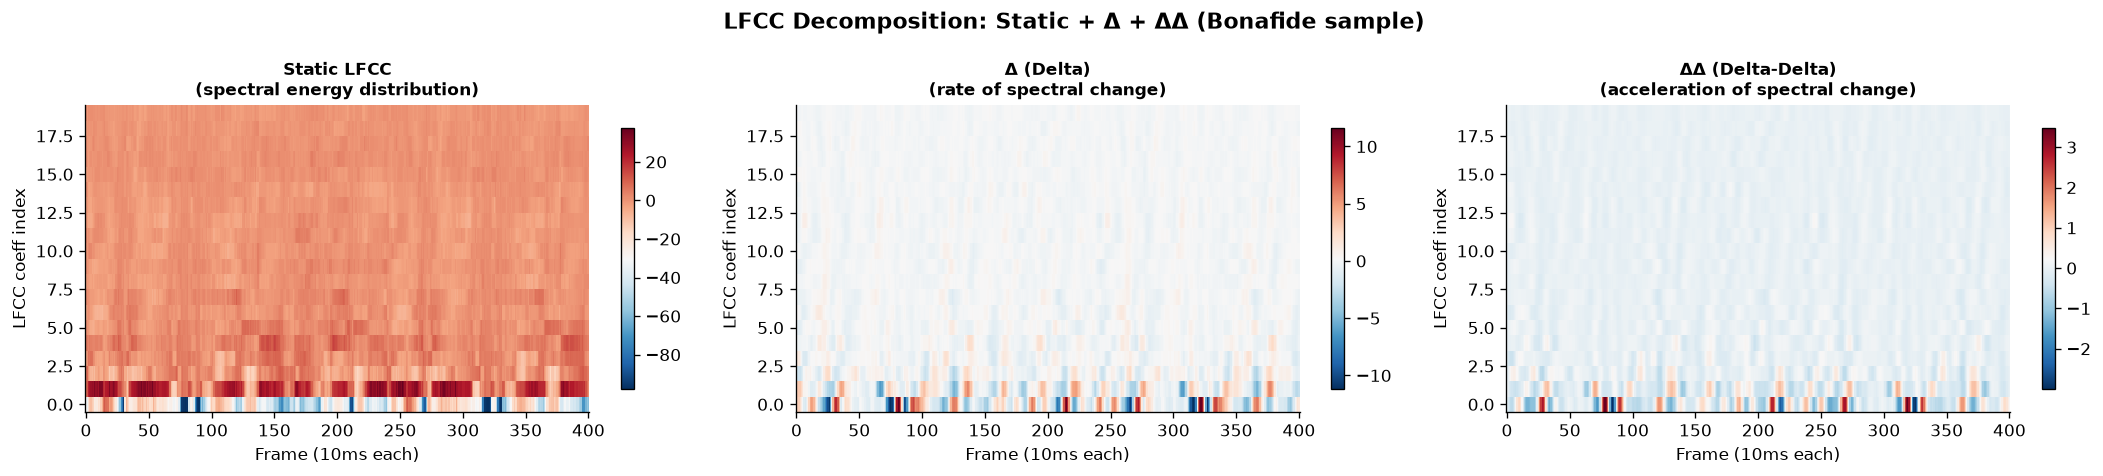

Combined shape: torch.Size([1, 60, 401])  → [B, 60, T] ✓


In [5]:
import torchaudio

# Re-run LFCC without delta combination to show each part
_lfcc_transform = torchaudio.transforms.LFCC(
    sample_rate=16000, n_filter=60, f_min=0.0, f_max=8000.0, n_lfcc=20,
    log_lf=True,
    speckwargs={'n_fft': 512, 'win_length': 400, 'hop_length': 160, 'window_fn': torch.hamming_window}
).to(device)
_delta_fn = torchaudio.transforms.ComputeDeltas(win_length=9, mode='replicate').to(device)

with torch.no_grad():
    static = _lfcc_transform(real_wf).squeeze(1)   # [1, 20, T]
    delta = _delta_fn(static)                       # [1, 20, T]
    delta2 = _delta_fn(delta)                       # [1, 20, T]

parts = [
    ('Static LFCC\n(spectral energy distribution)', static.squeeze(0).cpu().numpy()),
    ('Δ (Delta)\n(rate of spectral change)', delta.squeeze(0).cpu().numpy()),
    ('ΔΔ (Delta-Delta)\n(acceleration of spectral change)', delta2.squeeze(0).cpu().numpy()),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (title, data) in zip(axes, parts):
    im = ax.imshow(data, aspect='auto', origin='lower', cmap='RdBu_r', interpolation='nearest')
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.set_xlabel('Frame (10ms each)')
    ax.set_ylabel('LFCC coeff index')
    plt.colorbar(im, ax=ax, shrink=0.85)

plt.suptitle('LFCC Decomposition: Static + Δ + ΔΔ (Bonafide sample)', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print(f'Combined shape: {torch.cat([static, delta, delta2], dim=1).shape}  → [B, 60, T] ✓')

## 4. SpecAugment Visualization

/tmp/ipykernel_65289/2896509897.py:24: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  norm=Normalize(vmin=-np.abs(np.array(diff)).max(), vmax=np.abs(np.array(diff)).max()))


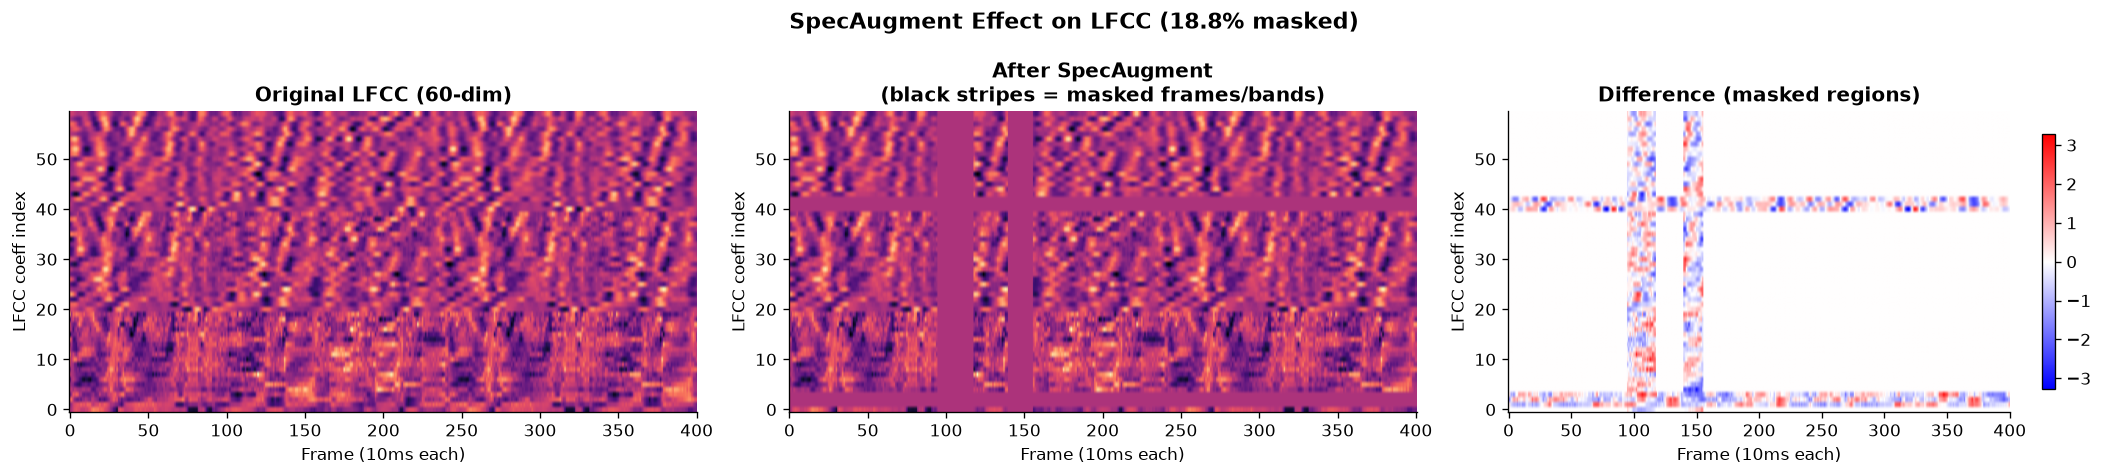

In [6]:
lfcc_ext = LFCCExtractor().to(device)
spec_aug = SpecAugment()

with torch.no_grad():
    lfcc_ext.eval()
    features_clean = lfcc_ext(real_wf).squeeze(0).cpu()  # [60, T]

# Apply SpecAugment in training mode
spec_aug.train()
torch.manual_seed(99)
features_augmented = spec_aug(features_clean.unsqueeze(0)).squeeze(0)  # [60, T]

diff = (features_augmented - features_clean)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].imshow(features_clean.numpy(), aspect='auto', origin='lower', cmap='magma')
axes[0].set_title('Original LFCC (60-dim)', fontweight='bold')

axes[1].imshow(features_augmented.numpy(), aspect='auto', origin='lower', cmap='magma')
axes[1].set_title('After SpecAugment\n(black stripes = masked frames/bands)', fontweight='bold')

im = axes[2].imshow(diff.numpy(), aspect='auto', origin='lower', cmap='bwr',
                     norm=Normalize(vmin=-np.abs(np.array(diff)).max(), vmax=np.abs(np.array(diff)).max()))
axes[2].set_title('Difference (masked regions)', fontweight='bold')
plt.colorbar(im, ax=axes[2], shrink=0.85)

for ax in axes:
    ax.set_xlabel('Frame (10ms each)')
    ax.set_ylabel('LFCC coeff index')

n_zeroed = (features_augmented == 0).sum().item()
total = features_augmented.numel()
plt.suptitle(f'SpecAugment Effect on LFCC ({100*n_zeroed/total:.1f}% masked)', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. CMVN: Before vs After Normalization

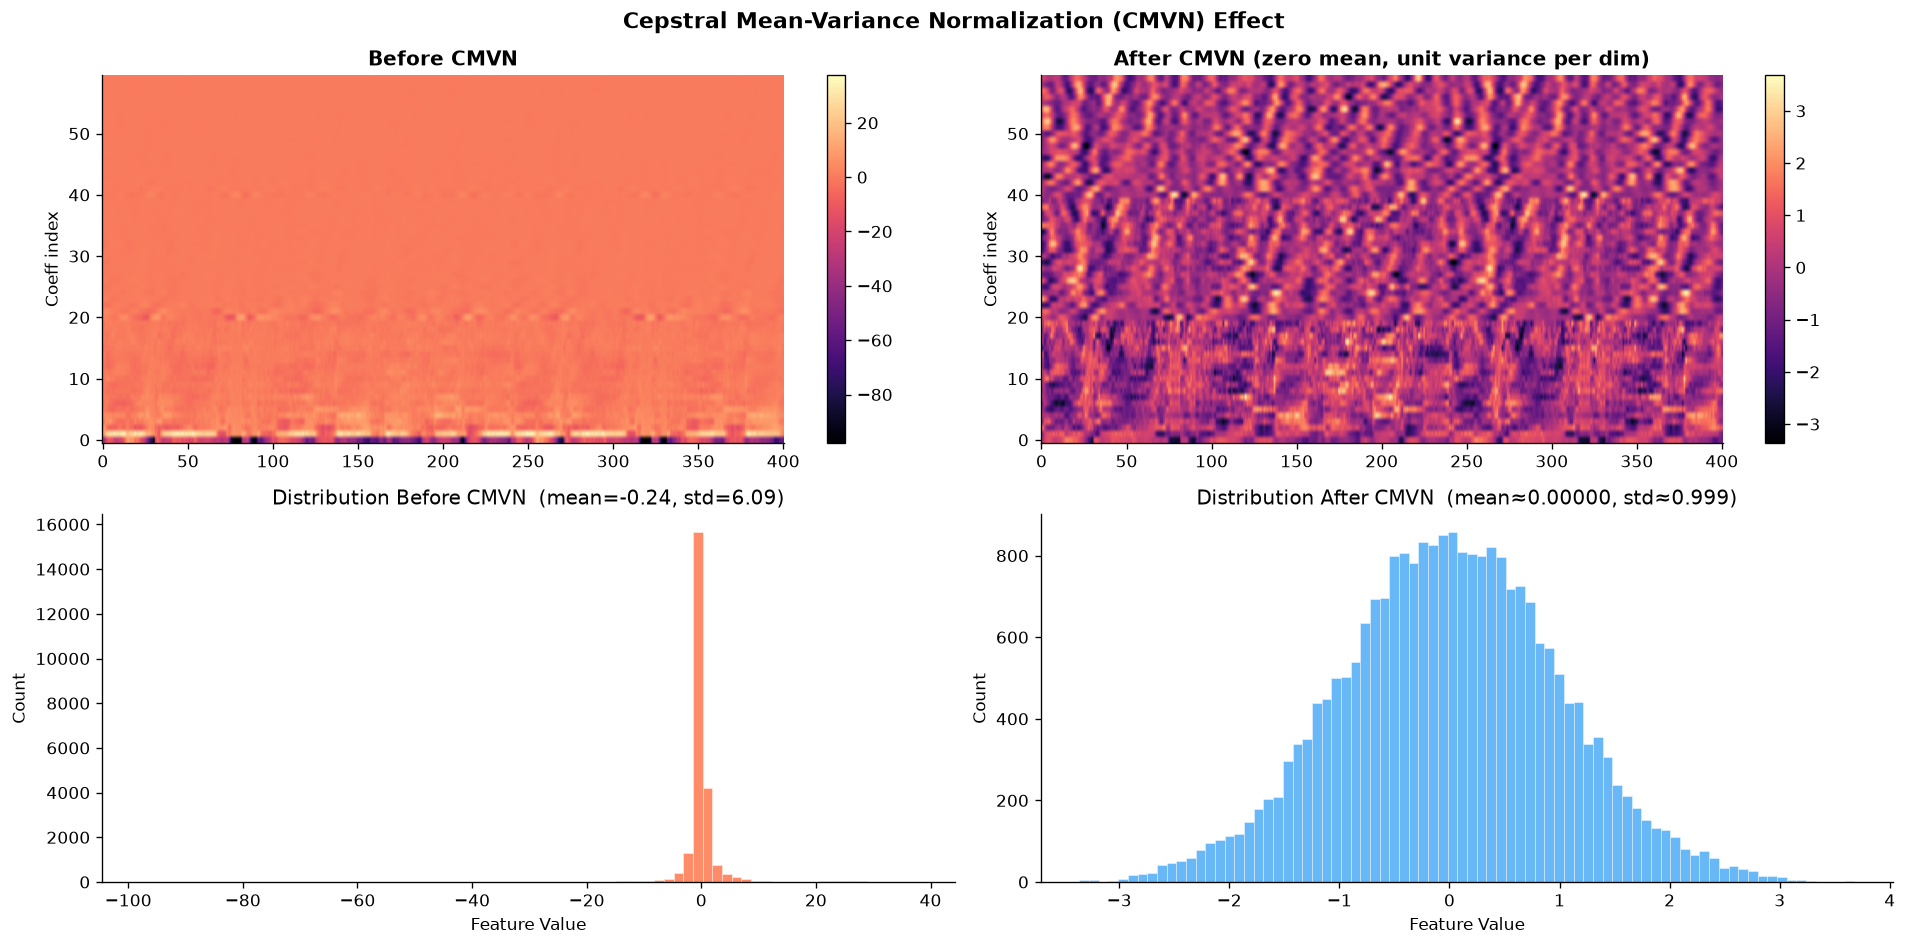

In [7]:
# Extract LFCC WITHOUT CMVN to compare
lfcc_no_cmvn = LFCCExtractor(apply_cmvn=False).to(device).eval()
lfcc_with_cmvn = LFCCExtractor(apply_cmvn=True).to(device).eval()

with torch.no_grad():
    raw = lfcc_no_cmvn(real_wf).squeeze(0).cpu().numpy()     # [60, T]
    normalized = lfcc_with_cmvn(real_wf).squeeze(0).cpu().numpy()  # [60, T]

fig, axes = plt.subplots(2, 2, figsize=(16, 8))

# Spectrograms
im0 = axes[0, 0].imshow(raw, aspect='auto', origin='lower', cmap='magma')
axes[0, 0].set_title('Before CMVN', fontweight='bold')
plt.colorbar(im0, ax=axes[0, 0])

im1 = axes[0, 1].imshow(normalized, aspect='auto', origin='lower', cmap='magma')
axes[0, 1].set_title('After CMVN (zero mean, unit variance per dim)', fontweight='bold')
plt.colorbar(im1, ax=axes[0, 1])

# Distribution plots
axes[1, 0].hist(raw.flatten(), bins=80, color='#FF7043', alpha=0.8, edgecolor='white', linewidth=0.3)
axes[1, 0].set_title(f'Distribution Before CMVN  (mean={raw.mean():.2f}, std={raw.std():.2f})')
axes[1, 0].set_xlabel('Feature Value')

axes[1, 1].hist(normalized.flatten(), bins=80, color='#42A5F5', alpha=0.8, edgecolor='white', linewidth=0.3)
axes[1, 1].set_title(f'Distribution After CMVN  (mean≈{normalized.mean():.5f}, std≈{normalized.std():.3f})')
axes[1, 1].set_xlabel('Feature Value')

for ax in axes.flat:
    ax.set_ylabel('Count' if ax in axes[1] else 'Coeff index')

plt.suptitle('Cepstral Mean-Variance Normalization (CMVN) Effect', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Temporal Statistics: Bonafide vs Spoof Over Time

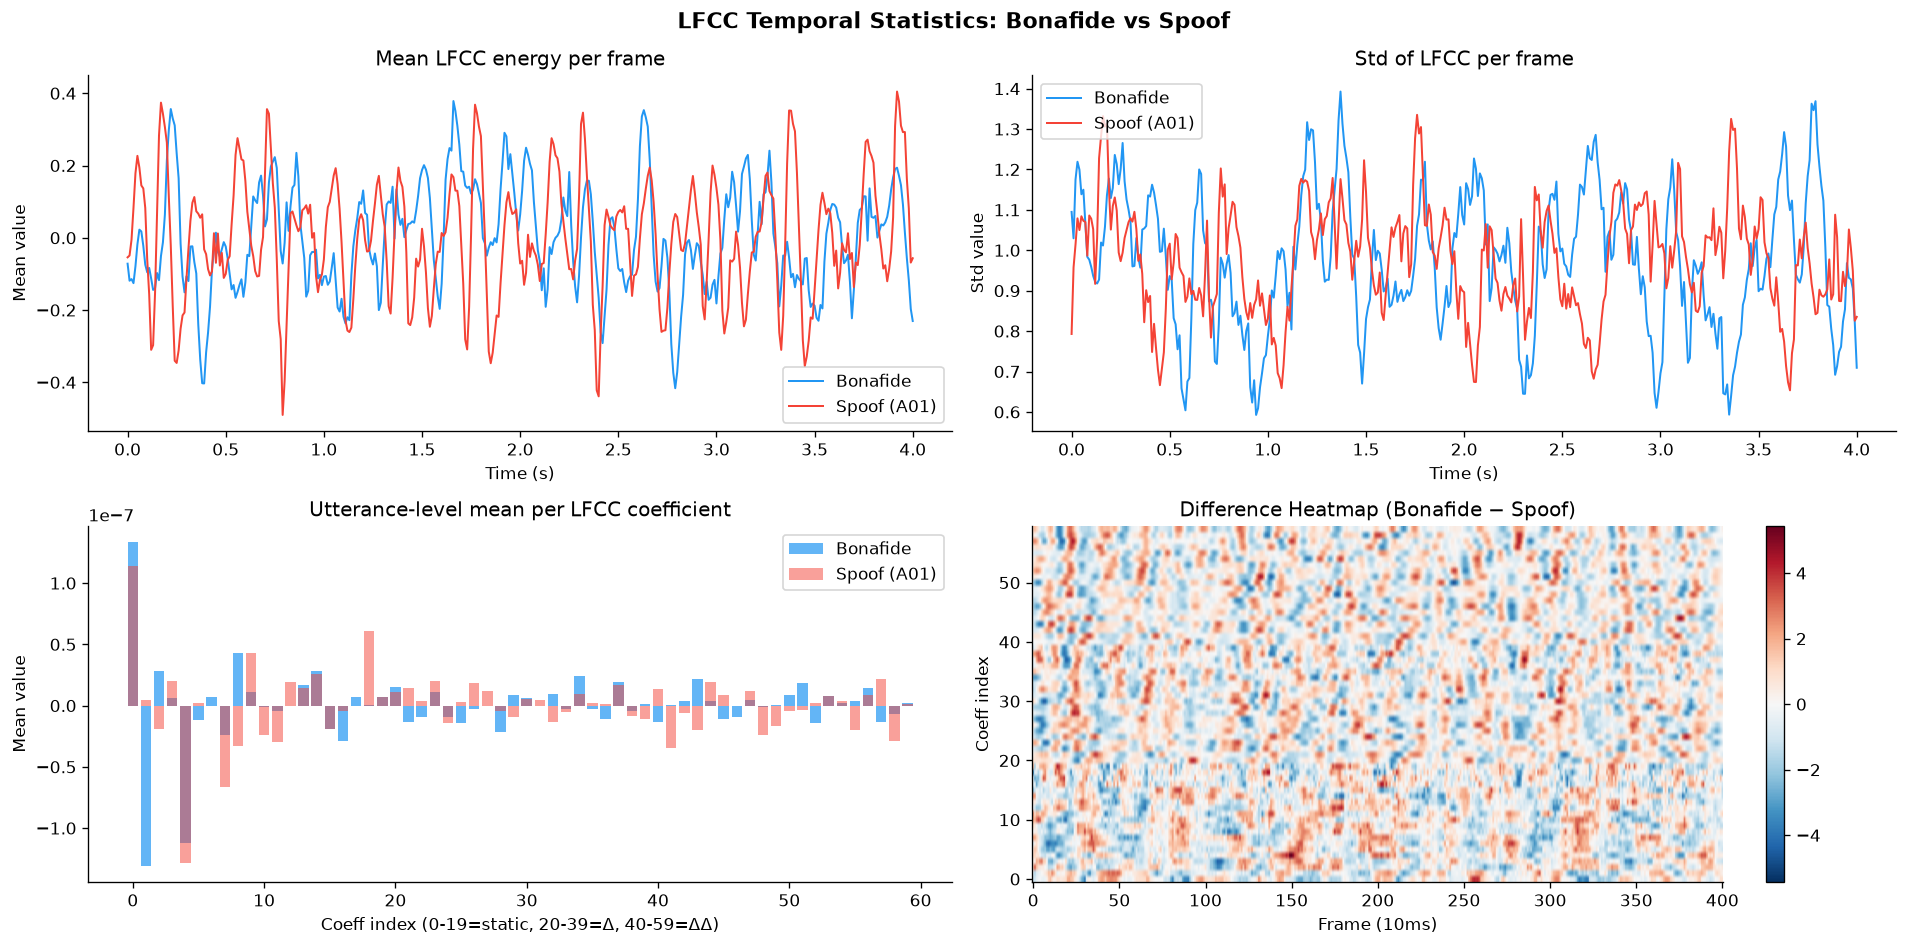

In [8]:
lfcc_ext = LFCCExtractor().to(device).eval()

with torch.no_grad():
    real_feat = lfcc_ext(real_wf).squeeze(0).cpu().numpy()  # [60, T]
    fake_feat = lfcc_ext(fake_wf).squeeze(0).cpu().numpy()

time_axis = np.arange(real_feat.shape[1]) * 0.01  # 10ms per frame

fig, axes = plt.subplots(2, 2, figsize=(16, 8))

# Mean energy per frame
axes[0, 0].plot(time_axis, real_feat.mean(axis=0), color='#2196F3', label='Bonafide', linewidth=1.2)
axes[0, 0].plot(time_axis, fake_feat.mean(axis=0), color='#F44336', label=f'Spoof ({fake_atk})', linewidth=1.2)
axes[0, 0].set_title('Mean LFCC energy per frame')
axes[0, 0].set_xlabel('Time (s)')
axes[0, 0].set_ylabel('Mean value')
axes[0, 0].legend()

# Std per frame
axes[0, 1].plot(time_axis, real_feat.std(axis=0), color='#2196F3', label='Bonafide', linewidth=1.2)
axes[0, 1].plot(time_axis, fake_feat.std(axis=0), color='#F44336', label=f'Spoof ({fake_atk})', linewidth=1.2)
axes[0, 1].set_title('Std of LFCC per frame')
axes[0, 1].set_xlabel('Time (s)')
axes[0, 1].set_ylabel('Std value')
axes[0, 1].legend()

# Feature mean per coefficient (utterance-level)
axes[1, 0].bar(range(60), real_feat.mean(axis=1), color='#2196F3', alpha=0.7, label='Bonafide')
axes[1, 0].bar(range(60), fake_feat.mean(axis=1), color='#F44336', alpha=0.5, label=f'Spoof ({fake_atk})')
axes[1, 0].set_title('Utterance-level mean per LFCC coefficient')
axes[1, 0].set_xlabel('Coeff index (0-19=static, 20-39=Δ, 40-59=ΔΔ)')
axes[1, 0].set_ylabel('Mean value')
axes[1, 0].legend()

# Difference heatmap (real - fake)
diff = real_feat - fake_feat
im = axes[1, 1].imshow(diff, aspect='auto', origin='lower', cmap='RdBu_r',
                        norm=Normalize(vmin=-np.abs(np.array(diff)).max(), vmax=np.abs(np.array(diff)).max()))
axes[1, 1].set_title('Difference Heatmap (Bonafide − Spoof)')
axes[1, 1].set_xlabel('Frame (10ms)')
axes[1, 1].set_ylabel('Coeff index')
plt.colorbar(im, ax=axes[1, 1])

plt.suptitle('LFCC Temporal Statistics: Bonafide vs Spoof', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Summary Table

In [9]:
print('=' * 70)
print('Feature Extractor Summary')
print('=' * 70)
print(f'{"Feature":<25} {"Dims":<8} {"Scale":<12} {"Expected EER":<15} {"Role"}')
print('-' * 70)
rows = [
    ('LFCC', 60, 'Linear',  '1.8–3.5%',  'PRIMARY (our model)'),
    ('Log-Mel', 80, 'Mel', '6.0–8.5%', 'ABLATION'),
    ('MFCC', 120, 'Mel+DCT', '8.5–12.0%', 'BASELINE comparison'),
]
for name, dims, scale, eer, role in rows:
    print(f'{name:<25} {dims:<8} {scale:<12} {eer:<15} {role}')
print('=' * 70)
print()
print('All shapes confirmed:')
print(f'  LFCC output:    [B, 60, 401]  (60 = 20 static + 20Δ + 20ΔΔ)')
print(f'  Log-Mel output: [B, 80, 401]')
print(f'  MFCC output:    [B, 120, 401]')
print(f'  T_frames = 401 for 64000-sample input, hop=160, n_fft=512')
print()
print('✅ Phase 2 Feature Extraction: COMPLETE')

Feature Extractor Summary
Feature                   Dims     Scale        Expected EER    Role
----------------------------------------------------------------------
LFCC                      60       Linear       1.8–3.5%        PRIMARY (our model)
Log-Mel                   80       Mel          6.0–8.5%        ABLATION
MFCC                      120      Mel+DCT      8.5–12.0%       BASELINE comparison

All shapes confirmed:
  LFCC output:    [B, 60, 401]  (60 = 20 static + 20Δ + 20ΔΔ)
  Log-Mel output: [B, 80, 401]
  MFCC output:    [B, 120, 401]
  T_frames = 401 for 64000-sample input, hop=160, n_fft=512

✅ Phase 2 Feature Extraction: COMPLETE
